In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv(next(iter(uploaded)))

Saving WA_Fn-UseC_-HR-Employee-Attrition 3.csv to WA_Fn-UseC_-HR-Employee-Attrition 3 (1).csv


In [3]:
print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  Jo

In [4]:
# Display all feature names

print("Total Features:", len(df.columns))

for column in df.columns:
    print(column)

Total Features: 35
Age
Attrition
BusinessTravel
DailyRate
Department
DistanceFromHome
Education
EducationField
EmployeeCount
EmployeeNumber
EnvironmentSatisfaction
Gender
HourlyRate
JobInvolvement
JobLevel
JobRole
JobSatisfaction
MaritalStatus
MonthlyIncome
MonthlyRate
NumCompaniesWorked
Over18
OverTime
PercentSalaryHike
PerformanceRating
RelationshipSatisfaction
StandardHours
StockOptionLevel
TotalWorkingYears
TrainingTimesLastYear
WorkLifeBalance
YearsAtCompany
YearsInCurrentRole
YearsSinceLastPromotion
YearsWithCurrManager


In [5]:
# Check missing values

missing_values = df.isnull().sum()

print("Missing Values:")
display(missing_values)

Missing Values:


,0
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


In [6]:
# Check duplicate records

print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [7]:
# Display target variable

print(df["Attrition"].value_counts())

Attrition
No     1233
Yes     237
Name: count, dtype: int64


In [8]:
# Numerical features

numerical_features = df.select_dtypes(
    include=["int64", "float64"]
).columns

print("Numerical Features:")
print(list(numerical_features))


# Categorical features

categorical_features = df.select_dtypes(
    include=["object"]
).columns

print("\nCategorical Features:")
print(list(categorical_features))

Numerical Features:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Categorical Features:
['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']


In [9]:
# Create Feature Dictionary

feature_dictionary = pd.DataFrame({
    "Feature Name": df.columns,
    "Data Type": df.dtypes.values,
    "Unique Values": [df[col].nunique() for col in df.columns],
    "Missing Values": [df[col].isnull().sum() for col in df.columns]
})

display(feature_dictionary)

,Feature Name,Data Type,Unique Values,Missing Values
0,Age,int64,43,0
1,Attrition,object,2,0
2,BusinessTravel,object,3,0
3,DailyRate,int64,886,0
4,Department,object,3,0
5,DistanceFromHome,int64,29,0
6,Education,int64,5,0
7,EducationField,object,6,0
8,EmployeeCount,int64,1,0
9,EmployeeNumber,int64,1470,0


In [10]:
feature_descriptions = {
    "Age": "Age of employee",
    "Attrition": "Whether employee left the company",
    "BusinessTravel": "Frequency of business travel",
    "DailyRate": "Daily salary rate",
    "Department": "Employee department",
    "DistanceFromHome": "Distance between home and workplace",
    "Education": "Employee education level",
    "EducationField": "Employee education specialization",
    "EnvironmentSatisfaction": "Satisfaction with work environment",
    "Gender": "Employee gender",
    "JobInvolvement": "Level of job involvement",
    "JobLevel": "Employee job level",
    "JobRole": "Employee job position",
    "JobSatisfaction": "Employee job satisfaction",
    "MaritalStatus": "Employee marital status",
    "MonthlyIncome": "Monthly employee income",
    "MonthlyRate": "Monthly rate",
    "NumCompaniesWorked": "Number of companies previously worked",
    "OverTime": "Whether employee works overtime",
    "PercentSalaryHike": "Percentage salary increase",
    "PerformanceRating": "Employee performance rating",
    "RelationshipSatisfaction": "Relationship satisfaction level",
    "TotalWorkingYears": "Total years of work experience",
    "TrainingTimesLastYear": "Training sessions attended last year",
    "WorkLifeBalance": "Work and personal life balance",
    "YearsAtCompany": "Years spent in current company",
    "YearsInCurrentRole": "Years in current job role",
    "YearsSinceLastPromotion": "Years since last promotion",
    "YearsWithCurrManager": "Years working with current manager"
}

feature_dictionary["Description"] = (
    feature_dictionary["Feature Name"]
    .map(feature_descriptions)
    .fillna("Additional employee-related information")
)

display(feature_dictionary)

,Feature Name,Data Type,Unique Values,Missing Values,Description
0,Age,int64,43,0,Age of employee
1,Attrition,object,2,0,Whether employee left the company
2,BusinessTravel,object,3,0,Frequency of business travel
3,DailyRate,int64,886,0,Daily salary rate
4,Department,object,3,0,Employee department
5,DistanceFromHome,int64,29,0,Distance between home and workplace
6,Education,int64,5,0,Employee education level
7,EducationField,object,6,0,Employee education specialization
8,EmployeeCount,int64,1,0,Additional employee-related information
9,EmployeeNumber,int64,1470,0,Additional employee-related information


In [11]:
feature_dictionary.to_csv(
    "Feature_Dictionary.csv",
    index=False
)

print("Feature Dictionary created successfully!")

Feature Dictionary created successfully!


In [12]:
from google.colab import files

files.download("Feature_Dictionary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
# Check missing values

missing = df.isnull().sum()

missing_df = pd.DataFrame({
    "Column": df.columns,
    "Missing Values": missing.values,
    "Percentage": (df.isnull().mean() * 100).round(2).values
})

display(missing_df)

,Column,Missing Values,Percentage
0,Age,0,0.0
1,Attrition,0,0.0
2,BusinessTravel,0,0.0
3,DailyRate,0,0.0
4,Department,0,0.0
5,DistanceFromHome,0,0.0
6,Education,0,0.0
7,EducationField,0,0.0
8,EmployeeCount,0,0.0
9,EmployeeNumber,0,0.0


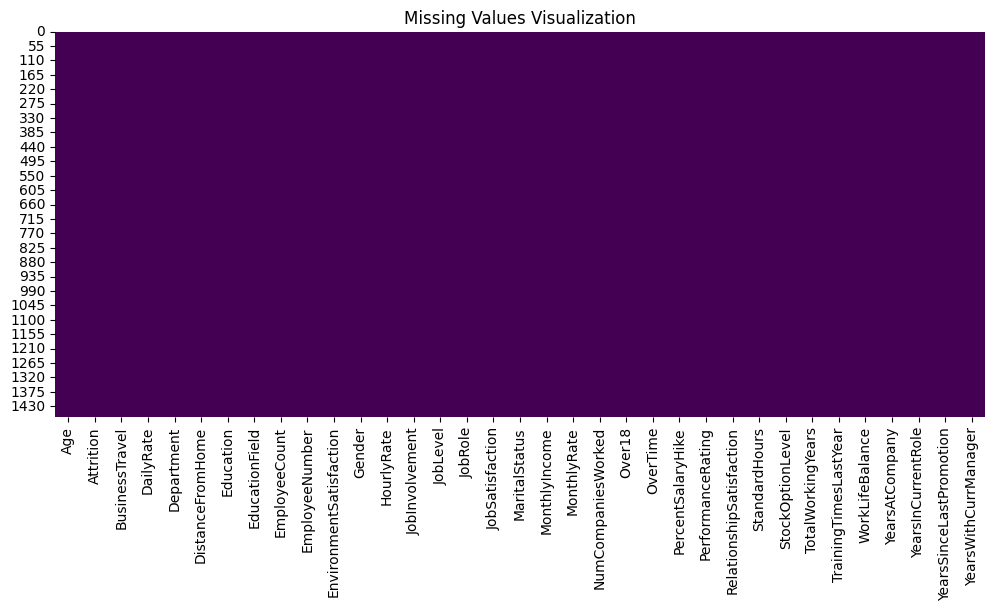

In [14]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap="viridis"
)

plt.title("Missing Values Visualization")
plt.show()

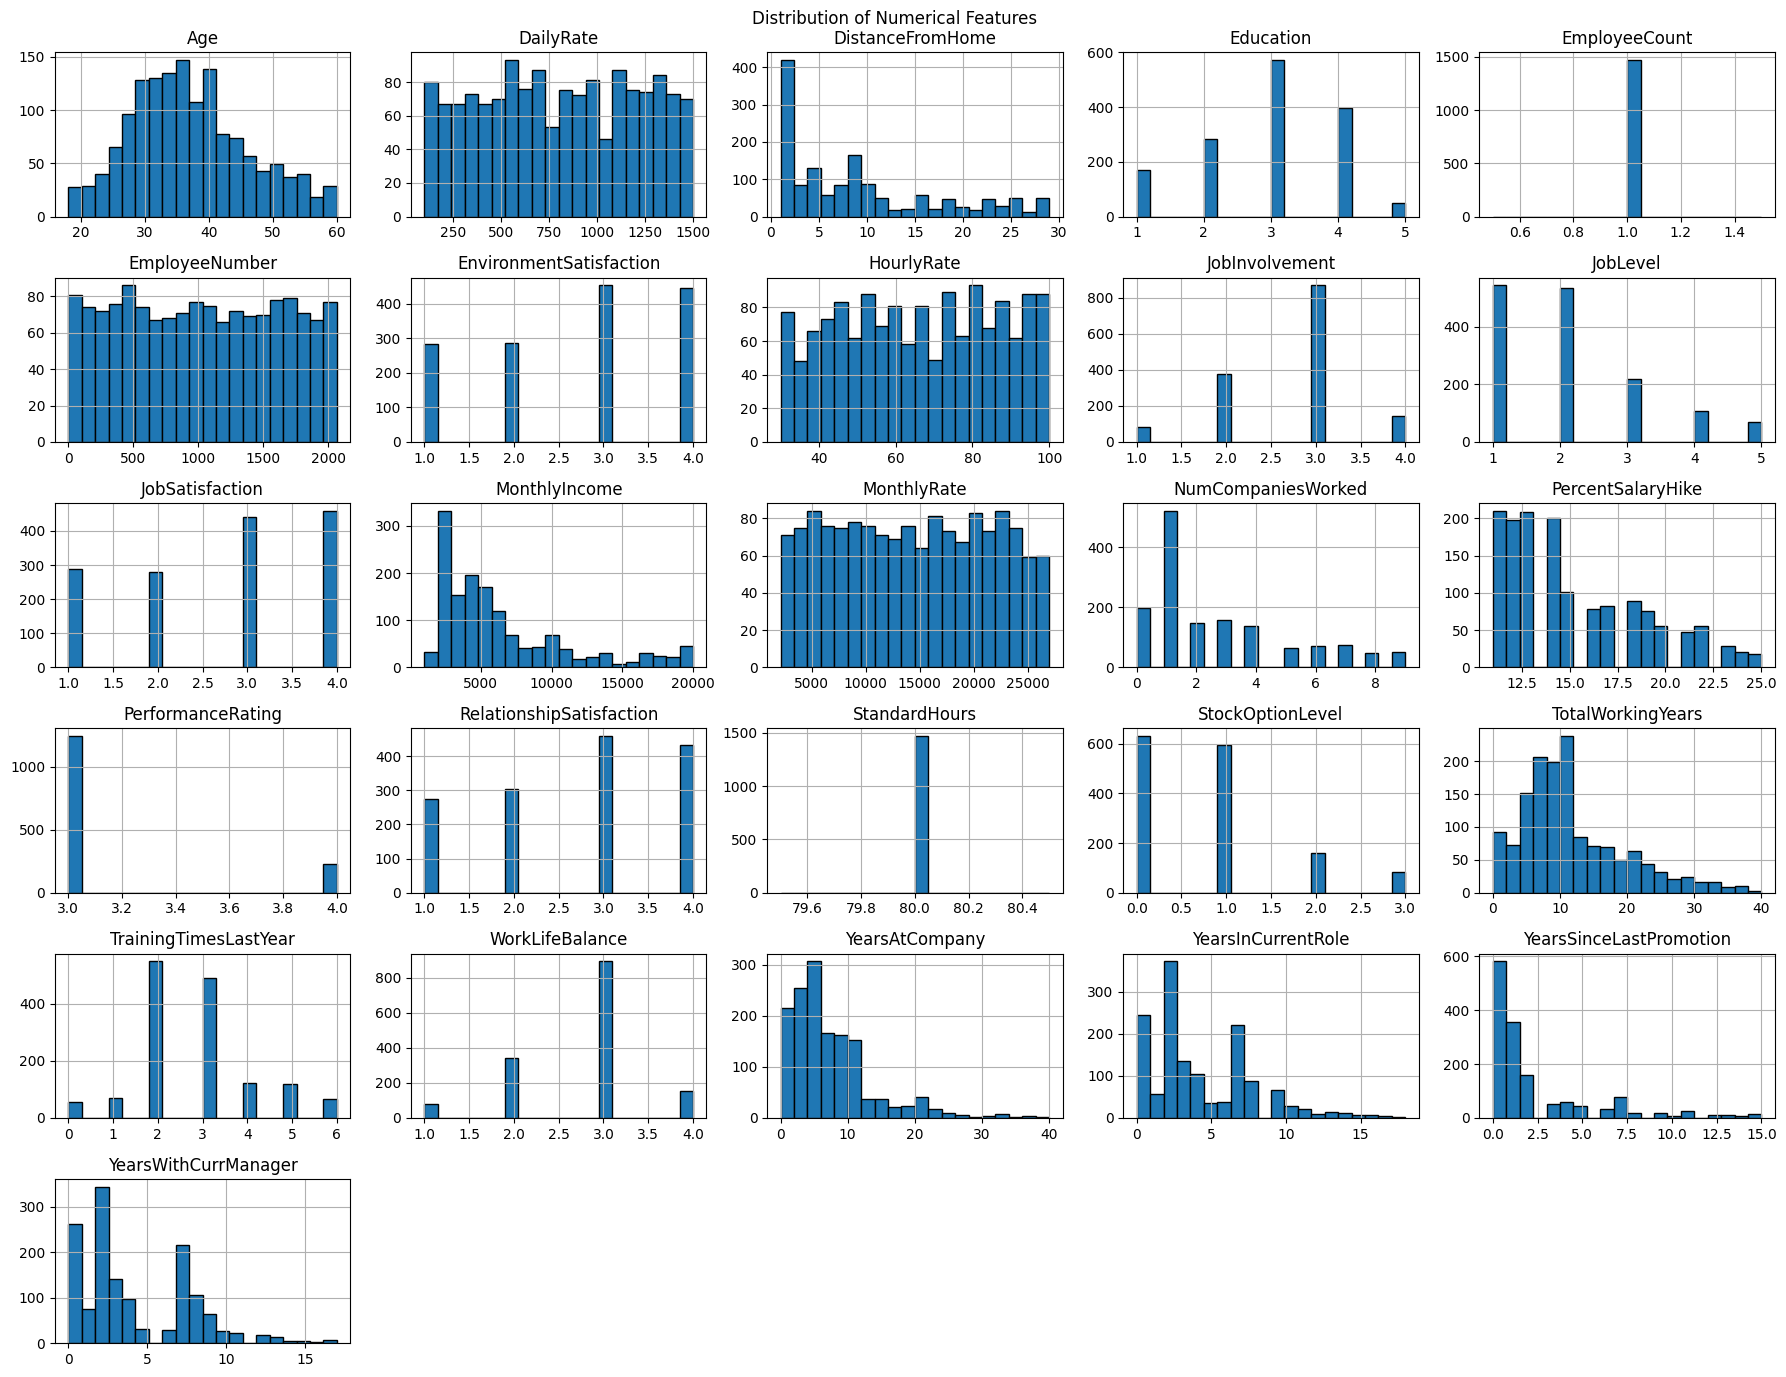

In [15]:
# Numerical feature distribution

numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

df[numerical_columns].hist(
    figsize=(18, 14),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

In [16]:
print(df["Attrition"].value_counts())

Attrition
No     1233
Yes     237
Name: count, dtype: int64


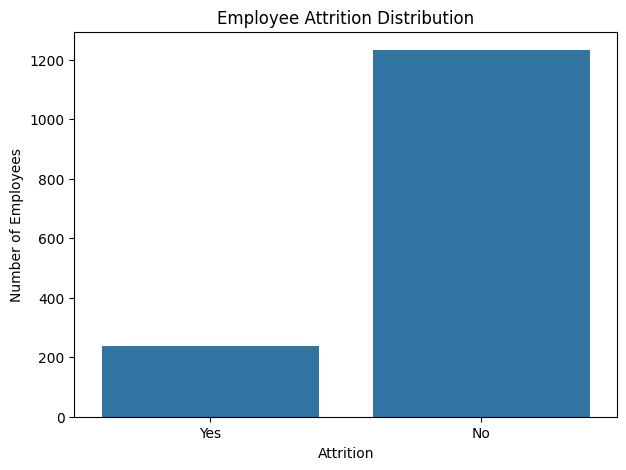

In [17]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Attrition"
)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

plt.show()

In [18]:
attrition_percentage = (
    df["Attrition"].value_counts(normalize=True) * 100
)

print("Attrition Percentage:")
print(attrition_percentage)

Attrition Percentage:
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


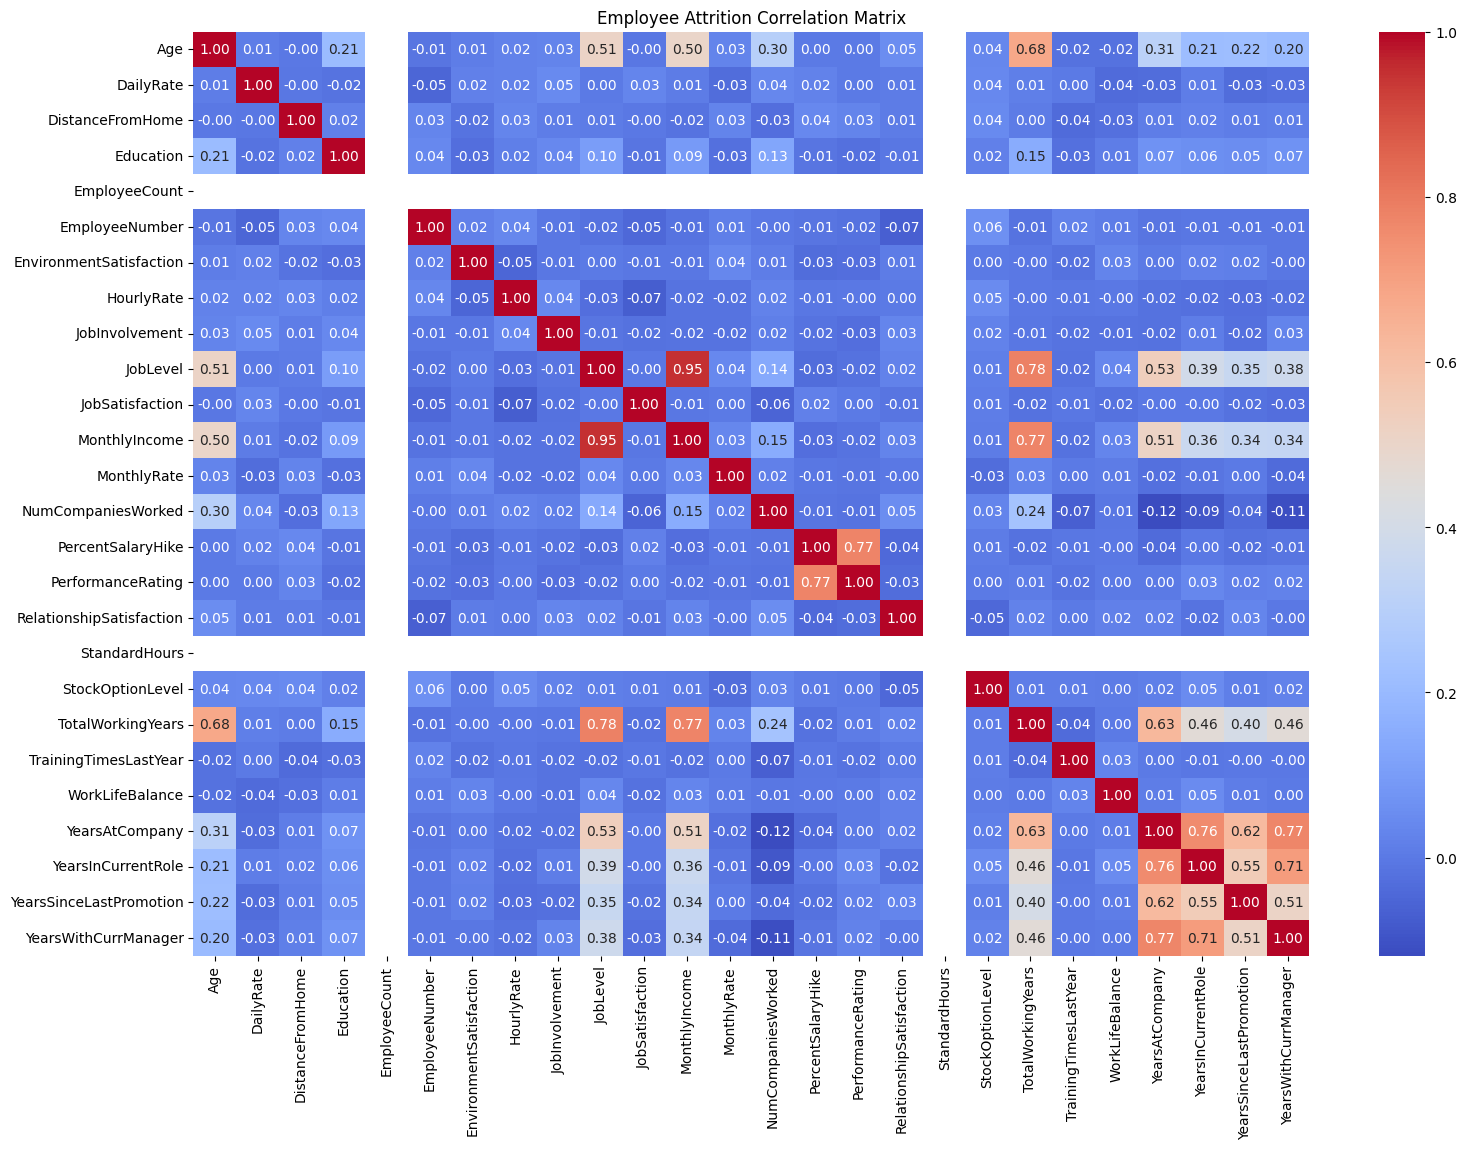

In [19]:
plt.figure(figsize=(18, 12))

correlation = df.select_dtypes(
    include=["int64", "float64"]
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Employee Attrition Correlation Matrix")
plt.show()

Attrition,No,Yes
Department,,
Human Resources,51,12
Research & Development,828,133
Sales,354,92


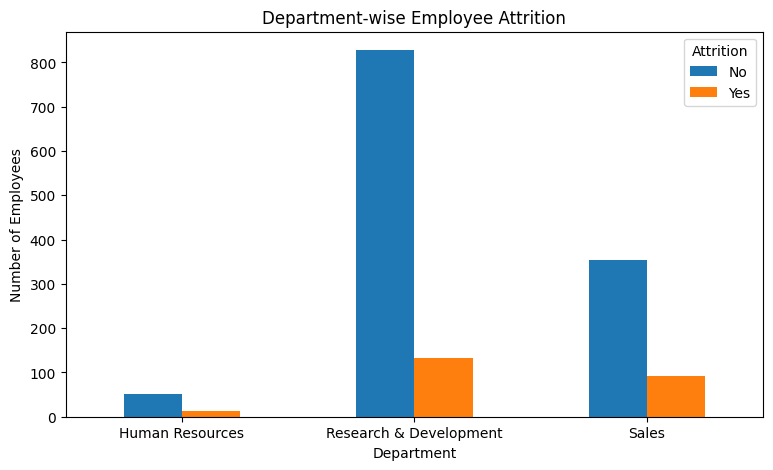

In [20]:
department_attrition = pd.crosstab(
    df["Department"],
    df["Attrition"]
)

display(department_attrition)

department_attrition.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Department-wise Employee Attrition")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.show()

# **Dataset Report**

Dataset Report
Dataset Name: IBM HR Analytics Employee Attrition & Performance

Dataset Description:

The dataset contains employee-related information such as age, department, job role, salary, job satisfaction, work experience and attrition status.

Dataset Information:
- Total records: 1,470 (original dataset).
- Total features: 35 (original dataset).
- Target variable: Attrition.
- Problem type: Binary Classification.
- Classes: Yes and No.
Dataset Analysis:

The dataset was analyzed to understand employee characteristics and attrition patterns. Missing values, duplicate records, numerical feature distributions, categorical features and correlations were examined using Python.

Conclusion:

The dataset provides useful information for studying employee attrition and understanding workforce patterns.

Note: These dimensions describe the standard original dataset. Verify them against your downloaded CSV.

# **Ethics Report**

Ethical Considerations
1. Data Privacy: Employee information must be protected from unauthorized access.
2. Data Security: Dataset files should be stored securely.
3. Bias and Fairness: Gender, age and other demographic attributes should not lead to unfair decisions.
4. Transparency: Analytical findings should be explained clearly.
5. Responsible Usage: Predictions should not be used to punish or discriminate against employees.
6. Human Oversight: HR decisions should involve human judgment.
7. Data Limitations: The dataset is an educational dataset and may not represent real organizations.
Conclusion
Ethical practices are important in HR analytics. Employee data should be handled responsibly, fairly and transparently.

# **Business Problem Statement**

Problem Statement
Employee attrition is an important challenge for organizations. When employees leave, organizations may experience recruitment costs, productivity loss and disruption in business operations.

The objective of this project is to analyze employee attrition using HR analytics. The project studies employee-related factors such as age, job satisfaction, salary, overtime, department and work experience.

The analysis helps understand attrition patterns and supports the development of better employee retention strategies.

# **Project Conclusion**

Conclusion
In this project, Employee Attrition Problem Definition and Planning was performed using Python and the IBM HR Analytics dataset.

The project covered business understanding, dataset understanding, feature dictionary creation, problem formulation and exploratory data analysis.

Different visualizations were created to understand missing values, feature distributions, employee attrition distribution and correlations between numerical features.

The project provides a foundation for future employee attrition prediction and HR analytics applications.

# Business Understanding

## 1. Business Case

Employee attrition refers to employees leaving an organization. High employee attrition can increase recruitment costs, reduce productivity and affect organizational performance.

This project analyzes employee data to understand attrition patterns and support better employee retention strategies.

## 2. HR Analytics

HR Analytics uses employee data to understand workforce behavior and improve human resource decisions.

It helps organizations analyze employee satisfaction, performance, salary, work experience and employee retention.

## 3. Employee Retention Strategies

- Improve employee satisfaction.
- Provide career development opportunities.
- Maintain work-life balance.
- Provide fair compensation.
- Improve communication between employees and managers.
- Conduct regular employee feedback surveys.

## 4. Business Stakeholders

- HR Managers
- HR Analysts
- Department Managers
- Senior Management
- Employees

## 5. Impact of Employee Attrition

- Increased recruitment costs.
- Loss of experienced employees.
- Reduced productivity.
- Increased workload for remaining employees.
- Loss of organizational knowledge.

## Conclusion

Business understanding helps identify the importance of employee attrition and explains how HR analytics can support employee retention.

# Problem Formulation

## 1. Problem Definition

The main objective of this project is to analyze and predict employee attrition using HR data.

The project identifies patterns in employee information that may be associated with employees leaving an organization.

## 2. Prediction Objective

- Input: Employee-related HR features.
- Target Variable: Attrition.
- Output: Yes or No.
- Problem Type: Supervised Machine Learning.
- Classification Type: Binary Classification.

## 3. Business KPIs

The following Key Performance Indicators (KPIs) are used to understand employee attrition:

1. **Employee Attrition Rate:** Percentage of employees who leave the organization.
2. **Employee Retention Rate:** Percentage of employees who remain in the organization.
3. **Department-wise Attrition:** Attrition rate across different departments.
4. **Job Role-wise Attrition:** Attrition rate across different job roles.
5. **Overtime-wise Attrition:** Attrition comparison between employees working overtime and those who do not.

## 4. Expected Outcome

The project aims to understand employee attrition patterns and provide insights that can help organizations improve employee satisfaction and retention.

## Conclusion

Problem formulation defines the objective, target variable, prediction type and business KPIs required for employee attrition analysis.

# Project Planning

## 1. Project Workflow

The following workflow describes the steps involved in completing the Employee Attrition Analysis project.

### Workflow Steps

1. Business Understanding
2. Dataset Collection
3. Dataset Understanding
4. Feature Dictionary Creation
5. Problem Formulation
6. Data Quality Analysis
7. Exploratory Data Analysis (EDA)
8. Missing Value Analysis
9. Feature Distribution Analysis
10. Attrition Distribution Analysis
11. Correlation Analysis
12. Report Preparation
13. GitHub Repository Submission

### Workflow Diagram

```text
       Business Understanding
                |
                v
        Dataset Collection
                |
                v
       Dataset Understanding
                |
                v
       Feature Dictionary
                |
                v
       Problem Formulation
                |
                v
        Data Quality Check
                |
                v
         Exploratory EDA
                |
                v
       Data Visualization
                |
                v
        Report Preparation
                |
                v
       GitHub Submission
```

# Project Roadmap

## Project Development Phases

### Phase 1: Business Understanding
- Understand employee attrition.
- Study HR analytics.
- Identify business stakeholders.
- Understand employee retention strategies.

### Phase 2: Dataset Understanding
- Collect the HR dataset.
- Review all dataset features.
- Create the Feature Dictionary.
- Identify the target variable.
- Identify numerical and categorical features.

### Phase 3: Problem Formulation
- Define the employee attrition problem.
- Identify the prediction objective.
- Define business KPIs.
- Identify ethical considerations.

### Phase 4: Exploratory Data Analysis
- Analyze missing values.
- Study feature distributions.
- Analyze attrition distribution.
- Generate a correlation matrix.
- Perform department-wise attrition analysis.

### Phase 5: Documentation
- Prepare the Business Problem Statement.
- Prepare the Dataset Report.
- Prepare the Ethics Report.
- Document the project workflow.

### Phase 6: GitHub Submission
- Create a GitHub repository.
- Upload the Google Colab notebook.
- Upload the Feature Dictionary CSV.
- Add project documentation.
- Submit the GitHub repository link.

## Expected Outcome

The project will provide an understanding of employee attrition patterns through HR analytics and exploratory data analysis. It will also establish a foundation for future employee attrition prediction projects.